In [1]:
import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.multitest import multipletests
from tqdm import tqdm

eps = 0.000001

save_tag = '26jul'

In [57]:
def iqr(x):
    return x.quantile(0.75) - x.quantile(0.25)

def mad(x):
    return np.median(np.abs(x - np.median(x)))

def rng(x):
    return x.max() - x.min()

def statistics(x):
    mean = np.mean(x)
    sd = np.std(x)
    median = np.median(x)
    q1 = np.percentile(x, 25)
    q3 = np.percentile(x, 75)
    iqr = q3 - q1
    return mean.item(), median.item(), sd.item(), iqr.item()


def remove_outlayer(x, method='3sigma', return_bin=True):
    mean, median, sd, iqr = statistics(x)
    if method == '3sigma':
        thr = 3               # 3 sigma
        z = (x - mean) / (sd + eps)
        binary = (z >= -thr) & (z <= thr)
        return binary if return_bin else x[binary]
    elif method == 'iqr':
        q1, q3 = np.percentile(x, [25, 75])
        binary = (x >= (q1 - 1.5*iqr)) &  (x <= (q3 + 1.5*iqr))
        return binary if return_bin else x[binary]
    else:
        print('Method not implemented')
        return None


def remove_outlayer_df(df, assay, method):
    """
    method = ('3sigma', 'iqr')
    """
    
    binary = []
    for i in df['Plate_ID'].unique():
        x = df.loc[df['Plate_ID'] == i, assay]
        binary.extend(remove_outlayer(x, method).tolist())
    binary = np.array(binary)
    df_new = df.loc[binary].copy()
    return df_new
    

def normalize(x, control, method='mean', scale=False):
    mean, median, sd, iqr = statistics(control)
    if not scale:
        sd, iqr = 1, 1
    if method == 'mean':
        return (x - mean) / sd if sd > eps else 0
    elif method == 'median':
        return (x - median) / (iqr) if iqr > eps else 0
    else:
        print('Method not implemented')
        return None


def normalize_df(df, df_ref, assay, method):
    df_ref[f'norm_{assay}'] = None
    for i in df_ref['Plate_ID'].unique():
        x = df.loc[df['Plate_ID'] == i, assay]
        control = df_ref.loc[df_ref['Plate_ID'] == i, assay]
        
        x = normalize(x, control, method=method, scale=False)
        df.loc[df['Plate_ID'] == i, f'norm_{assay}'] = x
        
        x = normalize(control, control, method=method, scale=False)
        df_ref.loc[df_ref['Plate_ID'] == i, f'norm_{assay}'] = x

    return df, df_ref
    

def emperical_p_value(x, null, alternative='two_sided', take_abs=False):
    if take_abs:
        null = np.abs(null)
        x = np.abs(x)
    if alternative == 'greater':
        p = np.sum(null >= x)
    elif alternative == 'less':
        p = np.sum(null <= x)
    elif  alternative == 'two_sided':
        p = np.sum(null >= x | null <= x)
    else:
        print('Invalid "alternative" parameter')

    # p = (p+1) / (len(null)+1)
    p = (p) / (len(null))
    return p


def boxplot_per_plate(df, assay, protein, title='', ordered=True, save_dir=None, ylim=None):
    # Plate-id orderes: 
    # to see original order use Plate_ID
    # to see them ordered based on numbers use Plate_ID_cat
    plate_id = 'Plate_ID_cat' if ordered else 'Plate_ID'
    
    plt.figure(figsize=(20, 6))

    df = df.loc[df['Protein'] == protein].copy()
    df['Plate_ID_cat'] = df['Plate_ID_cat'].cat.remove_unused_categories()
    
    n_plate = len(df[plate_id].unique())
    plt.vlines(np.arange(0, n_plate, 2), ymin = -100, ymax = 100, colors='gray', linestyles='dashed', linewidth=0.5)
    sns.boxplot(data=df, x=plate_id, y=assay)
    
    plt.title(f'{assay} {protein}, {title}')
    plt.xticks(rotation=90, size = 5)
    plt.xlabel('Plate ID')
    plt.ylabel(' '.join(assay.split('_')))
    plt.tight_layout()
    if ylim != None:
        plt.ylim(ylim)
    if save_dir != None:
        plt.savefig(save_dir)
    plt.show()
    plt.close()


def dotplot_per_plate(df, assay, protein, ids, title='', ordered=True, save_dir=None, ylim=None):
    
    plt.figure(figsize=(20, 6))
    df = df.loc[df['Protein'] == protein].copy()
    df['Plate_ID_cat'] = df['Plate_ID_cat'].cat.remove_unused_categories()
    
    n_plate = len(df['Plate_ID_cat'].unique())
    
    df = df.loc[df['ID'].isin(ids)]
    
    plt.vlines(np.arange(0, n_plate, 2), ymin = -30, ymax = 30, colors='gray', linestyles='dashed', linewidth=0.5)
    plt.hlines(0, xmin = 0, xmax = n_plate, colors='gray', linestyles='dashed', linewidth=0.5)
    
    sns.stripplot(data=df, x='Plate_ID_cat', y=assay, hue='ID', dodge=True, jitter=True, size=4)
    
    plt.title(f'{assay} {protein}, {title}')
    plt.xticks(rotation=90, size = 5)
    plt.xlabel('Plate ID')
    plt.ylabel(' '.join(assay.split('_')))
    plt.tight_layout()
    if ylim != None:
        plt.ylim(ylim)
    if save_dir != None:
        plt.savefig(save_dir)
    plt.show()
    plt.close()


def pos_ctrl_qc(df, protein, pos_ctrl, assay):
    df_tmp = df.loc[(df['Protein'] == protein) & (df['ID'] == pos_ctrl)].copy()
    x = remove_outlayer(np.array(df_tmp[assay]), method='iqr', return_bin=False)
    df_tmp[f'abnormal_{pos_ctrl}_{protein}_{assay}'] = 0
    df_tmp.loc[df_tmp[assay] > x.max(), f'abnormal_{pos_ctrl}_{assay}'] = 1
    df_tmp.loc[df_tmp[assay] < x.min(), f'abnormal_{pos_ctrl}_{assay}'] = 1
    df_qc_updated = df_tmp.groupby('Plate_ID')[f'abnormal_{pos_ctrl}_{assay}'].sum()
    return df_qc_updated

In [3]:
df_other = pd.read_csv(f"data/PO_processed_{save_tag}.csv", index_col=0, low_memory=False)
df_ctrl = pd.read_csv(f"data/PO_processed_dmso_{save_tag}.csv", index_col=0, low_memory=False)

In [4]:
# Outlier plates
with open("outlier_plates_23jul.txt", 'r') as file:
    outlier_plates = file.read()
outlier_plates = outlier_plates.split('\n')
print(len(outlier_plates))

66


In [5]:
print(df_other.shape)
print(df_ctrl.shape)

df_other = df_other.loc[~ df_other['Plate_ID'].isin(outlier_plates)].copy()
df_ctrl = df_ctrl.loc[~ df_ctrl['Plate_ID'].isin(outlier_plates)].copy()

print(df_other.shape)
print(df_ctrl.shape)

(146374, 40)
(7071, 40)
(142136, 40)
(6865, 40)


In [6]:
df_other_wt = df_other.loc[df_other['Protein'] == 'PAH-WT']
df_other_mut = df_other.loc[df_other['Protein'] == 'PAH-I65T']
df_ctrl_wt = df_ctrl.loc[df_ctrl['Protein'] == 'PAH-WT']
df_ctrl_mut = df_ctrl.loc[df_ctrl['Protein'] == 'PAH-I65T']

## Normality test

/Users/behnam/miniconda3/envs/chem/lib/python3.11/site-packages/scipy/stats/_axis_nan_policy.py:586: UserWarning: scipy.stats.shapiro: Input data has range zero. The results may not be accurate.
  res = hypotest_fun_out(*samples, **kwds)


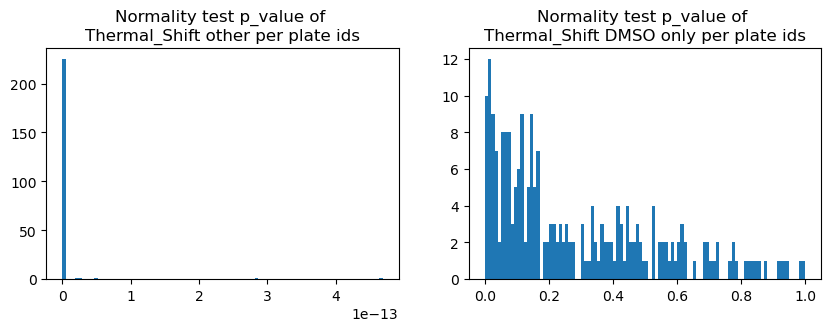

In [7]:
assay = 'Thermal_Shift'

norm_p_all = []
norm_p_ctrl = []
for i in df_other_wt['Plate_ID'].unique():
    x = df_other_wt.loc[df_other_wt['Plate_ID'] == i, assay]
    stat, p = stats.shapiro(x)
    norm_p_all.append(p)
    x = df_ctrl_wt.loc[df_ctrl_wt['Plate_ID'] == i, assay]
    stat, p = stats.shapiro(x)
    norm_p_ctrl.append(p)

norm_p_all = np.array(norm_p_all)
norm_p_ctrl = np.array(norm_p_ctrl)

fig, ax = plt.subplots(1, 2, figsize=(10,3))
ax[0].hist(norm_p_all, 100);
ax[1].hist(norm_p_ctrl, 100);
ax[0].set_title(f'Normality test p_value of \n{assay} other per plate ids');
ax[1].set_title(f'Normality test p_value of \n{assay} DMSO only per plate ids');

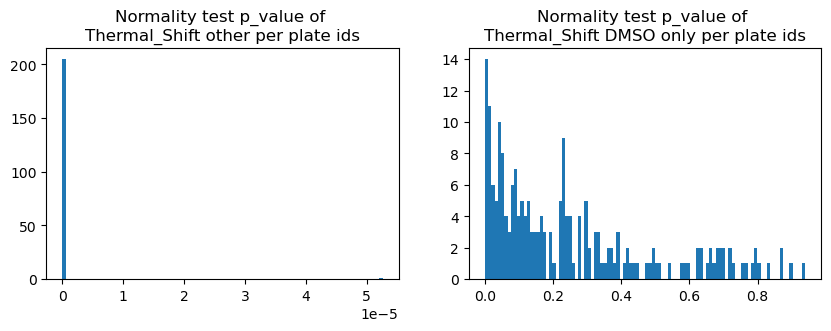

In [8]:
assay = 'Thermal_Shift'

norm_p_all = []
norm_p_ctrl = []
for i in df_other_mut['Plate_ID'].unique():
    x = df_other_mut.loc[df_other_mut['Plate_ID'] == i, assay]
    stat, p = stats.shapiro(x)
    norm_p_all.append(p)
    x = df_ctrl_mut.loc[df_ctrl_mut['Plate_ID'] == i, assay]
    stat, p = stats.shapiro(x)
    norm_p_ctrl.append(p)

norm_p_all = np.array(norm_p_all)
norm_p_ctrl = np.array(norm_p_ctrl)

fig, ax = plt.subplots(1, 2, figsize=(10,3))
ax[0].hist(norm_p_all, 100);
ax[1].hist(norm_p_ctrl, 100);
ax[0].set_title(f'Normality test p_value of \n{assay} other per plate ids');
ax[1].set_title(f'Normality test p_value of \n{assay} DMSO only per plate ids');

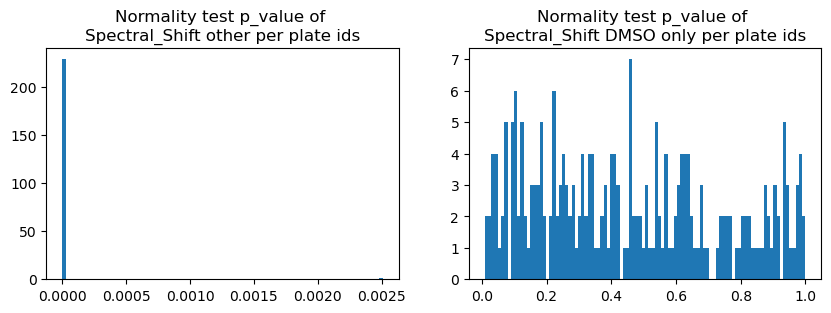

In [9]:
assay = 'Spectral_Shift'

norm_p_all = []
norm_p_ctrl = []
for i in df_other_wt['Plate_ID'].unique():
    x = df_other_wt.loc[df_other_wt['Plate_ID'] == i, assay]
    stat, p = stats.shapiro(x)
    norm_p_all.append(p)
    x = df_ctrl_wt.loc[df_ctrl_wt['Plate_ID'] == i, assay]
    stat, p = stats.shapiro(x)
    norm_p_ctrl.append(p)

norm_p_all = np.array(norm_p_all)
norm_p_ctrl = np.array(norm_p_ctrl)

fig, ax = plt.subplots(1, 2, figsize=(10,3))
ax[0].hist(norm_p_all, 100);
ax[1].hist(norm_p_ctrl, 100);
ax[0].set_title(f'Normality test p_value of \n{assay} other per plate ids');
ax[1].set_title(f'Normality test p_value of \n{assay} DMSO only per plate ids');

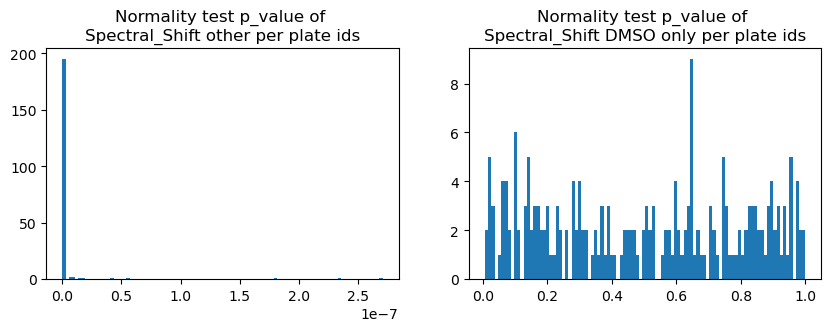

In [10]:
assay = 'Spectral_Shift'

norm_p_all = []
norm_p_ctrl = []
for i in df_other_mut['Plate_ID'].unique():
    x = df_other_mut.loc[df_other_mut['Plate_ID'] == i, assay]
    stat, p = stats.shapiro(x)
    norm_p_all.append(p)
    x = df_ctrl_mut.loc[df_ctrl_mut['Plate_ID'] == i, assay]
    stat, p = stats.shapiro(x)
    norm_p_ctrl.append(p)

norm_p_all = np.array(norm_p_all)
norm_p_ctrl = np.array(norm_p_ctrl)

fig, ax = plt.subplots(1, 2, figsize=(10,3))
ax[0].hist(norm_p_all, 100);
ax[1].hist(norm_p_ctrl, 100);
ax[0].set_title(f'Normality test p_value of \n{assay} other per plate ids');
ax[1].set_title(f'Normality test p_value of \n{assay} DMSO only per plate ids');

## Emperical test

100%|████████████████████████████████| 142136/142136 [00:07<00:00, 18235.60it/s]


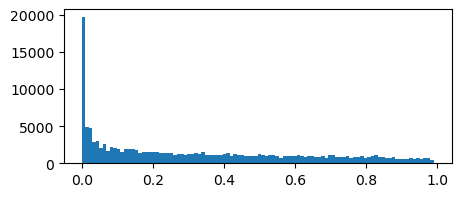

In [58]:
# Spectral_Shift p-value
assay = 'Spectral_Shift'

# Calculate p-values
df_other['SpSh_pval'] = np.nan

null_wt = df_ctrl_wt[f'delta_{assay}'].values
null_mut = df_ctrl_mut[f'delta_{assay}'].values

for i in tqdm(df_other.index):
    x = df_other.loc[i, f'delta_{assay}']
    
    protein = df_other.loc[i, 'Protein']
    null = null_wt if protein == 'PAH-WT' else null_mut
    
    p = emperical_p_value(x, null, alternative='greater', take_abs=True)
    df_other.loc[i, 'SpSh_pval'] = p

plt.figure(figsize=(5, 2))
plt.hist(df_other['SpSh_pval'], 100);

In [59]:
# Correct for multiple testting
df_other['SpSh_qval'] = 1
_, df_other.loc[df_other['Protein'] == 'PAH-WT', 'SpSh_qval'], _, _ = multipletests(df_other.loc[df_other['Protein'] == 'PAH-WT', 'SpSh_pval'], method='bonferroni')
_, df_other.loc[df_other['Protein'] == 'PAH-I65T', 'SpSh_qval'], _, _ = multipletests(df_other.loc[df_other['Protein'] == 'PAH-I65T', 'SpSh_pval'], method='bonferroni')


# _, df_other['SpSh_qval'], _, _ = multipletests(df_other['SpSh_pval'], method='fdr_bh')


df_other['bind_pval'] = df_other['SpSh_pval'] < .05
df_other['bind_qval'] = df_other['SpSh_qval'] < .05

In [60]:
df_other['bind_combined'] = 'weak_evidence'
df_other.loc[df_other['bind_qval'], 'bind_combined'] = 'strong_evidence'
df_other.loc[~df_other['bind_pval'], 'bind_combined'] = 'no_evidence'

In [63]:
df_other['SpSh_qval'].min()

np.int64(0)

In [64]:
# Filter out specific IDs
filtered_df = df_other.loc[(df_other['ID'].isin(['BH4', 'UCR243', 'UCR102'])) & (df_other['Protein'] == 'PAH-WT')]

summary_table = pd.pivot_table(
    filtered_df,
    index='ID',
    columns='bind_combined',
    values='Plate_ID',
    aggfunc='count',
    margins=True,
    margins_name='Total'
)

summary_table[['no_evidence', 'weak_evidence', 'strong_evidence', 'Total']]

bind_combined,no_evidence,weak_evidence,strong_evidence,Total
ID,,,,
BH4,3,15,442,460
UCR102,69,378,13,460
UCR243,92,366,2,460
Total,164,759,457,1380


In [65]:
# Filter out specific IDs
filtered_df = df_other.loc[(df_other['ID'].isin(['BH4', 'UCR243', 'UCR102'])) & (df_other['Protein'] == 'PAH-I65T')]

summary_table = pd.pivot_table(
    filtered_df,
    index='ID',
    columns='bind_combined',
    values='Plate_ID',
    aggfunc='count',
    margins=True,
    margins_name='Total'
)

summary_table[['no_evidence', 'weak_evidence', 'strong_evidence', 'Total']]

bind_combined,no_evidence,weak_evidence,strong_evidence,Total
ID,,,,
BH4,NaN,3.0,409.0,412
UCR102,24.0,372.0,16.0,412
UCR243,10.0,327.0,75.0,412
Total,34.0,702.0,500.0,1236


In [66]:
s1 = set(df_other.loc[(df_other['Protein'] == 'PAH-WT') & (df_other['bind_qval']), 'ID'].unique())
s2 = set(df_other.loc[(df_other['Protein'] == 'PAH-I65T') & (df_other['bind_qval']), 'ID'].unique())
len(s1.intersection(s2))

633

100%|█████████████████████████████████| 142136/142136 [00:14<00:00, 9974.22it/s]


Text(0.5, 1.0, 'TSA_pval_destabilizer')

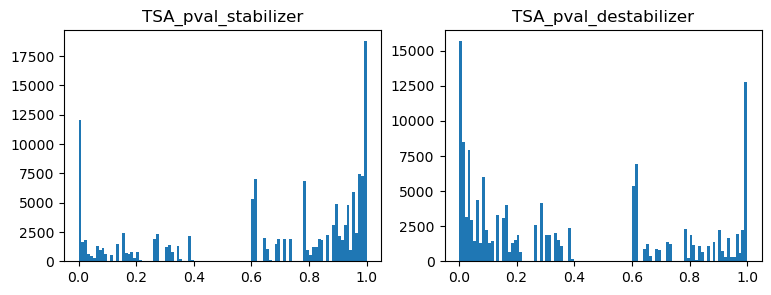

In [95]:
assay = 'Thermal_Shift'

df_other['TSA_pval_stabilizer'] = np.nan
df_other['TSA_pval_destabilizer'] = np.nan

null_wt = df_ctrl_wt[f'delta_{assay}'].values
null_mut = df_ctrl_mut[f'delta_{assay}'].values

for i in tqdm(df_other.index):
    x = df_other.loc[i, f'delta_{assay}']

    protein = df_other.loc[i, 'Protein']
    null = null_wt if protein == 'PAH-WT' else null_mut
    
    p = emperical_p_value(x, null, alternative='greater', take_abs=False)
    df_other.loc[i, 'TSA_pval_stabilizer'] = p
    p = emperical_p_value(x, null, alternative='less', take_abs=False)
    df_other.loc[i, 'TSA_pval_destabilizer'] = p

fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].hist(df_other['TSA_pval_stabilizer'], 100);
ax[0].set_title('TSA_pval_stabilizer')
ax[1].hist(df_other['TSA_pval_destabilizer'], 100);
ax[1].set_title('TSA_pval_destabilizer')

In [139]:
df_other['TSA_qval_stabilizer'] = 1
df_other['TSA_qval_destabilizer'] = 1
_, df_other.loc[df_other['Protein'] == 'PAH-WT', 'TSA_qval_stabilizer'], _, _ = multipletests(df_other.loc[df_other['Protein'] == 'PAH-WT', 'TSA_pval_stabilizer'], method='bonferroni')
_, df_other.loc[df_other['Protein'] == 'PAH-I65T', 'TSA_qval_stabilizer'], _, _ = multipletests(df_other.loc[df_other['Protein'] == 'PAH-I65T', 'TSA_pval_stabilizer'], method='bonferroni')
_, df_other.loc[df_other['Protein'] == 'PAH-WT', 'TSA_qval_destabilizer'], _, _ = multipletests(df_other.loc[df_other['Protein'] == 'PAH-WT', 'TSA_pval_destabilizer'], method='bonferroni')
_, df_other.loc[df_other['Protein'] == 'PAH-I65T', 'TSA_qval_destabilizer'], _, _ = multipletests(df_other.loc[df_other['Protein'] == 'PAH-I65T', 'TSA_pval_destabilizer'], method='bonferroni')

df_other['stabilize_pval'] = df_other['TSA_pval_stabilizer'] < .05
df_other['stabilize_qval'] = df_other['TSA_qval_stabilizer'] < .01
df_other['destabilize_pval'] = df_other['TSA_pval_destabilizer'] < .05
df_other['destabilize_qval'] = df_other['TSA_qval_destabilizer'] < .01

In [140]:
df_other['stabilize_combined'] = 'weak_evidence'
df_other.loc[df_other['stabilize_qval'], 'stabilize_combined'] = 'strong_evidence'
df_other.loc[~df_other['stabilize_pval'], 'stabilize_combined'] = 'no_evidence'

df_other['destabilize_combined'] = 'weak_evidence'
df_other.loc[df_other['destabilize_qval'], 'destabilize_combined'] = 'strong_evidence'
df_other.loc[~df_other['destabilize_pval'], 'destabilize_combined'] = 'no_evidence'

In [141]:
# Filter out specific IDs
filtered_df = df_other.loc[df_other['ID'].isin(['BH4', 'UCR243', 'UCR102'])]

summary_table = pd.pivot_table(
    filtered_df,
    index='ID',
    columns='stabilize_combined',
    values='Plate_ID',
    aggfunc='count',
    margins=True,
    margins_name='Total'
)

summary_table[['no_evidence', 'weak_evidence', 'strong_evidence', 'Total']]

stabilize_combined,no_evidence,weak_evidence,strong_evidence,Total
ID,,,,
BH4,454,23,395,872
UCR102,55,583,234,872
UCR243,40,284,548,872
Total,549,890,1177,2616


In [142]:
# Filter out specific IDs
filtered_df = df_other.loc[df_other['ID'].isin(['BH4', 'UCR243', 'UCR102'])]

summary_table = pd.pivot_table(
    filtered_df,
    index='ID',
    columns='destabilize_combined',
    values='Plate_ID',
    aggfunc='count',
    margins=True,
    margins_name='Total'
)

summary_table[['no_evidence', 'weak_evidence', 'strong_evidence', 'Total']]

destabilize_combined,no_evidence,weak_evidence,strong_evidence,Total
ID,,,,
BH4,753,110,9,872
UCR102,868,2,2,872
UCR243,868,1,3,872
Total,2489,113,14,2616


In [143]:
# Filter out specific IDs
filtered_df = df_other.loc[~df_other['ID'].isin(['BH4', 'UCR243', 'UCR102'])]

summary_table = pd.pivot_table(
    filtered_df,
    index='ID',
    columns='destabilize_combined',
    values='Plate_ID',
    aggfunc='count',
    margins=True,
    margins_name='Total'
)

summary_table[['no_evidence', 'weak_evidence', 'strong_evidence', 'Total']]

destabilize_combined,no_evidence,weak_evidence,strong_evidence,Total
ID,,,,
CSCS00000000223,2.0,NaN,NaN,2
CSCS00000001360,1.0,1.0,NaN,2
CSCS00000002033,2.0,NaN,NaN,2
CSCS00000002216,2.0,NaN,NaN,2
CSCS00000002301,2.0,NaN,NaN,2
...,...,...,...,...
CSCS00133154406,NaN,1.0,NaN,1
CSCS00133154427,1.0,NaN,1.0,2
CSCS00133154429,2.0,NaN,NaN,2


In [144]:
## Add Binding_validated_by_TSA
conversion_dict = {
    ('strong_evidence', 'strong_evidence', 'strong_evidence') : 'strong_evidence',
    ('strong_evidence', 'strong_evidence', 'weak_evidence')   : 'strong_evidence',
    ('strong_evidence', 'strong_evidence', 'no_evidence')     : 'strong_evidence',
    ('strong_evidence', 'weak_evidence',   'strong_evidence') : 'strong_evidence',
    ('strong_evidence', 'weak_evidence',   'weak_evidence')   : 'strong_evidence',
    ('strong_evidence', 'weak_evidence',   'no_evidence')     : 'strong_evidence',
    ('strong_evidence', 'no_evidence',     'strong_evidence') : 'strong_evidence',
    ('strong_evidence', 'no_evidence',     'weak_evidence')   : 'strong_evidence',
    ('strong_evidence', 'no_evidence',     'no_evidence')     : 'weak_evidence',
    ('weak_evidence',   'strong_evidence', 'strong_evidence') : 'weak_evidence',
    ('weak_evidence',   'strong_evidence', 'weak_evidence')   : 'weak_evidence',
    ('weak_evidence',   'strong_evidence', 'no_evidence')     : 'strong_evidence',
    ('weak_evidence',   'weak_evidence',   'strong_evidence') : 'weak_evidence',
    ('weak_evidence',   'weak_evidence',   'weak_evidence')   : 'weak_evidence',
    ('weak_evidence',   'weak_evidence',   'no_evidence')     : 'weak_evidence',
    ('weak_evidence',   'no_evidence',     'strong_evidence') : 'strong_evidence',
    ('weak_evidence',   'no_evidence',     'weak_evidence')   : 'weak_evidence',
    ('weak_evidence',   'no_evidence',     'no_evidence')     : 'weak_evidence',
    ('no_evidence',     'strong_evidence', 'strong_evidence') : 'weak_evidence',
    ('no_evidence',     'strong_evidence', 'weak_evidence')   : 'weak_evidence',
    ('no_evidence',     'strong_evidence', 'no_evidence')     : 'weak_evidence',
    ('no_evidence',     'weak_evidence',   'strong_evidence') : 'weak_evidence',
    ('no_evidence',     'weak_evidence',   'weak_evidence')   : 'weak_evidence',
    ('no_evidence',     'weak_evidence',   'no_evidence')     : 'weak_evidence',
    ('no_evidence',     'no_evidence',     'strong_evidence') : 'weak_evidence',
    ('no_evidence',     'no_evidence',     'weak_evidence')   : 'weak_evidence',
    ('no_evidence',     'no_evidence',     'no_evidence')     : 'no_evidence',
}

## Add groups
conversion_dict_group = {
    ('strong_evidence', 'strong_evidence', 'strong_evidence') : 'group1',
    ('strong_evidence', 'strong_evidence', 'weak_evidence')   : 'group2',
    ('strong_evidence', 'strong_evidence', 'no_evidence')     : 'group3',
    ('strong_evidence', 'weak_evidence',   'strong_evidence') : 'group4',
    ('strong_evidence', 'weak_evidence',   'weak_evidence')   : 'group5',
    ('strong_evidence', 'weak_evidence',   'no_evidence')     : 'group6',
    ('strong_evidence', 'no_evidence',     'strong_evidence') : 'group0',
    ('strong_evidence', 'no_evidence',     'weak_evidence')   : 'group0',
    ('strong_evidence', 'no_evidence',     'no_evidence')     : 'group7',
    ('weak_evidence',   'strong_evidence', 'strong_evidence') : 'group0',
    ('weak_evidence',   'strong_evidence', 'weak_evidence')   : 'group0',
    ('weak_evidence',   'strong_evidence', 'no_evidence')     : 'group0',
    ('weak_evidence',   'weak_evidence',   'strong_evidence') : 'group0',
    ('weak_evidence',   'weak_evidence',   'weak_evidence')   : 'group0',
    ('weak_evidence',   'weak_evidence',   'no_evidence')     : 'group0',
    ('weak_evidence',   'no_evidence',     'strong_evidence') : 'group0',
    ('weak_evidence',   'no_evidence',     'weak_evidence')   : 'group0',
    ('weak_evidence',   'no_evidence',     'no_evidence')     : 'group0',
    ('no_evidence',     'strong_evidence', 'strong_evidence') : 'group0',
    ('no_evidence',     'strong_evidence', 'weak_evidence')   : 'group0',
    ('no_evidence',     'strong_evidence', 'no_evidence')     : 'group0',
    ('no_evidence',     'weak_evidence',   'strong_evidence') : 'group0',
    ('no_evidence',     'weak_evidence',   'weak_evidence')   : 'group0',
    ('no_evidence',     'weak_evidence',   'no_evidence')     : 'group0',
    ('no_evidence',     'no_evidence',     'strong_evidence') : 'group0',
    ('no_evidence',     'no_evidence',     'weak_evidence')   : 'group0',
    ('no_evidence',     'no_evidence',     'no_evidence')     : 'group0',
}

In [145]:
# Add a new column bind_tsa
bind_tsa = [(i, j, k) for i, j, k in zip(
    df_other['bind_combined'], 
    df_other['stabilize_combined'], 
    df_other['destabilize_combined']
)]
df_other['bind_tsa'] = bind_tsa
df_other['bind_tsa'] = pd.Categorical(df_other['bind_tsa'], categories=list(conversion_dict.keys()), ordered=True)

In [147]:
# Filter out specific IDs
filtered_df = df_other.loc[(df_other['ID'].isin(['BH4', 'UCR243', 'UCR102'])) & (df_other['Protein'] == 'PAH-WT')]

summary_table = pd.pivot_table(
    filtered_df,
    index='bind_tsa',
    columns='ID',
    values='Plate_ID',
    aggfunc='count',
    margins=True,
    margins_name='Total'
)

summary_table#[['no_evidence', 'weak_evidence', 'strong_evidence', 'Total']]

/var/folders/g9/1n3d85nn2d14mq2r60k26ddc0000gn/T/ipykernel_88295/3447088966.py:4: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  summary_table = pd.pivot_table(


ID,BH4,UCR102,UCR243,Total
bind_tsa,,,,
"(strong_evidence, strong_evidence, strong_evidence)",0,0,0,NaN
"(strong_evidence, strong_evidence, weak_evidence)",0,0,0,NaN
"(strong_evidence, strong_evidence, no_evidence)",3,1,0,4.0
"(strong_evidence, weak_evidence, strong_evidence)",0,0,0,NaN
"(strong_evidence, weak_evidence, weak_evidence)",0,0,0,NaN
"(strong_evidence, weak_evidence, no_evidence)",8,12,2,22.0
"(strong_evidence, no_evidence, strong_evidence)",7,0,0,7.0
"(strong_evidence, no_evidence, weak_evidence)",106,0,0,106.0
"(strong_evidence, no_evidence, no_evidence)",318,0,0,318.0


In [148]:
# Filter out specific IDs
filtered_df = df_other.loc[(df_other['ID'].isin(['BH4', 'UCR243', 'UCR102'])) & (df_other['Protein'] == 'PAH-I65T')]

summary_table = pd.pivot_table(
    filtered_df,
    index='bind_tsa',
    columns='ID',
    values='Plate_ID',
    aggfunc='count',
    margins=True,
    margins_name='Total'
)

summary_table#[['no_evidence', 'weak_evidence', 'strong_evidence', 'Total']]

/var/folders/g9/1n3d85nn2d14mq2r60k26ddc0000gn/T/ipykernel_88295/3243618149.py:4: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  summary_table = pd.pivot_table(


ID,BH4,UCR102,UCR243,Total
bind_tsa,,,,
"(strong_evidence, strong_evidence, strong_evidence)",0,0,0,NaN
"(strong_evidence, strong_evidence, weak_evidence)",0,0,0,NaN
"(strong_evidence, strong_evidence, no_evidence)",390,3,71,464.0
"(strong_evidence, weak_evidence, strong_evidence)",0,0,0,NaN
"(strong_evidence, weak_evidence, weak_evidence)",0,0,0,NaN
"(strong_evidence, weak_evidence, no_evidence)",14,13,4,31.0
"(strong_evidence, no_evidence, strong_evidence)",1,0,0,1.0
"(strong_evidence, no_evidence, weak_evidence)",1,0,0,1.0
"(strong_evidence, no_evidence, no_evidence)",3,0,0,3.0


In [149]:
df_other['Binding_validated_by_TSA'] = df_other['bind_tsa'].map(conversion_dict)
df_other['Binding_group'] = df_other['bind_tsa'].map(conversion_dict_group)

In [153]:
# Filter out specific IDs
filtered_df = df_other.loc[(df_other['ID'].isin(['BH4', 'UCR243', 'UCR102'])) & (df_other['Protein'] == 'PAH-WT')]

summary_table = pd.pivot_table(
    filtered_df,
    index='ID',
    columns='Binding_validated_by_TSA',
    values='Plate_ID',
    aggfunc='count',
    margins=True,
    margins_name='Total'
)

summary_table[['no_evidence', 'weak_evidence', 'strong_evidence', 'Total']]

Binding_validated_by_TSA,no_evidence,weak_evidence,strong_evidence,Total
ID,,,,
BH4,2,334,124,460
UCR102,8,369,83,460
UCR243,13,287,160,460
Total,23,990,367,1380


In [154]:
# Filter out specific IDs
filtered_df = df_other.loc[(df_other['ID'].isin(['BH4', 'UCR243', 'UCR102'])) & (df_other['Protein'] == 'PAH-I65T')]

summary_table = pd.pivot_table(
    filtered_df,
    index='ID',
    columns='Binding_validated_by_TSA',
    values='Plate_ID',
    aggfunc='count',
    margins=True,
    margins_name='Total'
)

summary_table[['no_evidence', 'weak_evidence', 'strong_evidence', 'Total']]

Binding_validated_by_TSA,no_evidence,weak_evidence,strong_evidence,Total
ID,,,,
BH4,NaN,4.0,408.0,412
UCR102,NaN,261.0,151.0,412
UCR243,3.0,39.0,370.0,412
Total,3.0,304.0,929.0,1236


In [156]:
# Filter out specific IDs
filtered_df = df_other.loc[~df_other['ID'].isin(['BH4', 'UCR243', 'UCR102'])]

summary_table = pd.pivot_table(
    filtered_df,
    index='Protein',
    columns='Binding_validated_by_TSA',
    values='Plate_ID',
    aggfunc='count',
    margins=True,
    margins_name='Total'
)

summary_table[['no_evidence', 'weak_evidence', 'strong_evidence', 'Total']]

Binding_validated_by_TSA,no_evidence,weak_evidence,strong_evidence,Total
Protein,,,,
PAH-I65T,32927,30735,2258,65920
PAH-WT,36568,34054,2978,73600
Total,69495,64789,5236,139520


In [157]:
s1 = set(df_other.loc[(df_other['Protein'] == 'PAH-WT') & (df_other['Binding_validated_by_TSA'] == 'strong_evidence'), 'ID'].unique())
s2 = set(df_other.loc[(df_other['Protein'] == 'PAH-I65T') & (df_other['Binding_validated_by_TSA'] == 'strong_evidence'), 'ID'].unique())
len(s1.intersection(s2))

992

In [25]:
print(save_tag)
df_other.to_csv(f"data/PO_norm_analysed_stat_{save_tag}.csv")

23jul


In [158]:
s1

{'CSCS00027203025',
 'CSCS00026008346',
 'CSCS00027435319',
 'CSCS00026647378',
 'CSCS00028229003',
 'CSCS00133097340',
 'CSCS00133064397',
 'CSCS00027244890',
 'CSCS00028002892',
 'CSCS00026598906',
 'CSCS00027828555',
 'CSCS00104918718',
 'CSCS00133100132',
 'CSCS00027203772',
 'CSCS00027033754',
 'CSCS00133089966',
 'CSCS00133114517',
 'CSCS00027585165',
 'CSCS00026718242',
 'CSCS00026377416',
 'CSCS00133078302',
 'CSCS00026262649',
 'CSCS00027850017',
 'BH4',
 'CSCS00027981583',
 'CSCS00058130003',
 'CSCS00028229923',
 'CSCS00133143074',
 'CSCS00025927387',
 'CSCS00026645576',
 'CSCS00028199845',
 'CSCS00102901446',
 'CSCS00027842215',
 'CSCS00028299215',
 'CSCS00027794223',
 'CSCS00027252077',
 'CSCS00027635534',
 'CSCS00027786983',
 'CSCS00028062058',
 'CSCS00026557395',
 'CSCS00026971543',
 'CSCS00133081156',
 'CSCS00028200173',
 'CSCS00028200512',
 'CSCS00025981885',
 'CSCS00026205358',
 'CSCS00085094847',
 'CSCS00027686123',
 'CSCS00028065633',
 'CSCS00073300054',
 'CSCS001331